# Lab 03: How to write the agent loop

**Notebook 1 of 2: meet the loop on an envelope hunt**

## Goal

Write the loop that lets a model work through a question one step at a time: call the model, run the tool it asks
for, send the result back, and repeat until it answers. We play an envelope hunt. Each envelope holds a clue to the
next one, so nobody can say in advance how many must be opened, not us and not the model. One tool call run by hand
ends with the model asking for another envelope and no code left to open it. The loop closes that gap. Then we look
at how a loop ends: with the model's answer, or with a turn cap of our own when the hunt has no end.

Nothing here touches the music shop yet. This notebook is the playground; notebook 2 runs the same loop at the
Chinook support desk.

## What you will learn

- How to run one tool call by hand on the Chat Completions API, and why one is not enough for this question.
- How to turn those steps into a loop that stops when a reply has no tool call in it.
- How to read a finished run from its message list, and why every call sends more tokens than the one before.
- How to read the loop as a drawing: the step the model does, the steps our code does, and the two exits.
- How to add a turn cap, and tell a run that ended with an answer from a run the cap stopped.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


One client for the whole notebook, with a 60-second limit on each request, so a request that gets stuck fails
quickly. (The default is ten minutes.)

In [2]:
import json
from openai import OpenAI, omit

client = OpenAI(timeout=60)

Every model call in this notebook has two things in common:

- We call the model with **Chat Completions** (`client.chat.completions.create`). It is the plain form of a model
  call, and the best place to see the loop with nothing hidden. Agent frameworks run this same loop for us, most
  of them on OpenAI's newer Responses API.
- Every call passes `reasoning_effort=EFFORT or omit`. `EFFORT` is the setting the first cell printed. `omit` leaves
  the argument out of the request when `models.env` sets no effort, for a model that does not take one.

---

## Part A: Ask a question that needs an unknown number of steps

Five numbered envelopes lie on a table. One holds a prize. The others hold a clue or nothing. The only way to find
the prize is to open an envelope, read it, and go where it says.

The envelopes are a Python dictionary: the number is the key, and what is inside is the value. `SYSTEM` is the
system prompt, the rules of the game for the model. It already names a tool called `open_envelope`, which does not
exist yet.

In [3]:
ENVELOPES = {
    1: "Clue: look in envelope 4.",
    2: "The prize! Two tickets to the cinema.",
    3: "This envelope is empty.",
    4: "Clue: look in envelope 2.",
    5: "This envelope is empty.",
}

SYSTEM = (
    "You are playing an envelope hunt. A prize is hidden in one of the numbered envelopes. "
    "Open envelopes with open_envelope and follow the clues. Answer in one sentence."
)
QUESTION = "Where is the prize? Start with envelope 1."

### One model call, no tools

We send the rules and the question, and nothing else. `messages` is a list of dictionaries, one per message, each
with a `role` (who is speaking) and a `content` (what they say). The reply's text is in
`response.choices[0].message.content`.

In [4]:
response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": QUESTION},
    ],
    reasoning_effort=EFFORT or omit,
)

print(response.choices[0].message.content)

I’ll start by opening envelope 1.


In our run the model wrote that it will start by opening envelope 1. Nothing was opened. The reply is one sentence
of text, and nothing in this request can open an envelope. On another run the model may say instead that it cannot
open envelopes. Either way we have no prize.

A model can only write from two things: its training data and what we put in the request. What is inside our
envelopes is in neither. To play, the model needs something that can open an envelope, and that something has to be
our code.

### A plain Python function that opens an envelope

`open_envelope` is ordinary Python. Its first line prints a message every time it runs. That print is how we will
know, for the rest of this notebook, that a tool really ran. Its second line returns what the dictionary holds
for that number. `ENVELOPES.get(number, ...)` returns the second argument when the number is not a key, so a
number with no envelope gets a sentence instead of an error.

In [5]:
def open_envelope(number: int) -> str:
    """Open one envelope and read what is inside."""
    print(f"TOOL CALLED: open_envelope({number})")
    return ENVELOPES.get(number, "There is no envelope with that number.")

Before any model is involved, we play the hunt ourselves. We open envelope 1, and then whichever envelope each
clue names.

In [6]:
print(open_envelope(1))
print(open_envelope(4))
print(open_envelope(2))

TOOL CALLED: open_envelope(1)
Clue: look in envelope 4.
TOOL CALLED: open_envelope(4)
Clue: look in envelope 2.
TOOL CALLED: open_envelope(2)
The prize! Two tickets to the cinema.


Each call prints its `TOOL CALLED` line and then what the envelope holds. Envelope 1 sent us to 4, 4 sent us to 2,
and 2 holds the prize.

**Notice** the order. We could not open envelope 4 before we had read envelope 1, because we did not know it was
next. Each step needs the result of the step before. This hunt took three steps. Another hunt could take two, or
ten, and we would only find out by playing.

**Checkpoint A.** Without a tool the model cannot say where the prize is. Called by hand, `open_envelope` prints
`TOOL CALLED` three times, and the third envelope, number 2, holds the prize.

---

## Part B: Run one tool call by hand, and see where it stops

We have a model that cannot open anything and a function that can. This part connects them with our own code, one
step at a time.

### Describe the function to the model

**Important:** the model never sees our Python. `open_envelope` lives on our machine. What we send is a description
of it, a **tool schema**, inside `tools=[...]`:

- `name`: what the model writes to ask for this tool.
- `description`: what the tool is for. The model chooses tools by reading this.
- `parameters`: the arguments, as a JSON Schema. Here one whole number called `number`.
- `strict: True`: the model's arguments must match the schema exactly, so `number` is never missing. Strict mode
  needs every argument listed in `required` and `additionalProperties` set to `False`.

In [7]:
tools = [
    {
        "type": "function",
        "function": {
            "name": "open_envelope",
            "description": "Open one envelope and read what is inside.",
            "parameters": {
                "type": "object",
                "properties": {
                    "number": {"type": "integer", "description": "The envelope's number"}
                },
                "required": ["number"],
                "additionalProperties": False,
            },
            "strict": True,
        },
    }
]

### The model asks for the tool

The same rules and question, and now `tools=tools`. This time we keep the messages in a variable, `messages`,
because we are going to add to the list.

We print three things from the reply: its `finish_reason` (why the model stopped writing), its `content` (the text),
and its `tool_calls`.

In [8]:
messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": QUESTION},
]

response = client.chat.completions.create(
    model=MODEL, messages=messages, tools=tools, reasoning_effort=EFFORT or omit
)
reply = response.choices[0].message

print("finish_reason:", response.choices[0].finish_reason)
print("content:      ", reply.content)
for call in reply.tool_calls:
    print("tool call:    ", call.function.name, call.function.arguments, "| id:", call.id)

finish_reason: tool_calls
content:       None
tool call:     open_envelope {"number":1} | id: call_p6DDHqhivXe3GynEpYbwvI34


Read the reply field by field:

- `finish_reason` is `tool_calls`. The model stopped because it is asking for a tool, not because it finished an
  answer.
- `content` is `None`. There is no text at all.
- The tool call names `open_envelope`, and its `arguments` are a **string** of JSON, `{"number":1}`. The model
  wrote that string from the question.
- `id` labels this request, so that our answer can say which request it answers.

**Notice** what did not happen: no `TOOL CALLED` line was printed. The model asked. Nothing ran.

### Our code runs the function and sends the result back

Five small steps, all ours:

1. Add the model's reply to `messages`. The request for a tool has to be in the list before its result.
2. `json.loads` turns the arguments string into a Python dictionary.
3. `open_envelope(**args)` runs the function with it. `**args` passes `{"number": 1}` as `number=1`.
4. Add the result to `messages` as a message with the role `tool`. Its `tool_call_id` is the `id` of the call it
   answers.
5. Send the whole list to the model again.

In [9]:
messages.append(reply)

call = reply.tool_calls[0]
args = json.loads(call.function.arguments)
result = open_envelope(**args)
messages.append({"role": "tool", "tool_call_id": call.id, "content": result})

response = client.chat.completions.create(
    model=MODEL, messages=messages, tools=tools, reasoning_effort=EFFORT or omit
)
reply = response.choices[0].message

print("finish_reason:", response.choices[0].finish_reason)
print("content:      ", reply.content)
for call in reply.tool_calls or []:
    print("tool call:    ", call.function.name, call.function.arguments)

TOOL CALLED: open_envelope(1)


finish_reason: tool_calls
content:       None
tool call:     open_envelope {"number":4}


This time `TOOL CALLED` is printed, by our own line `open_envelope(**args)`. Then the model's second reply:

- `finish_reason` is `tool_calls` again, and `content` is `None` again.
- The tool call asks for envelope 4: `{"number":4}`.

We have done everything one tool call needs: the model asked, our code ran the function, the result went back.
And we still have no answer. The model read the clue from envelope 1 and asked for the next envelope, and no line
of ours is left to open it.

We could copy the cell and run it again. How many times? We cannot know. **Only the model's next reply says whether
another round is needed.** That is a job for a loop.

**Checkpoint B.** The first reply has `finish_reason` `tool_calls`, `content` `None` and one call to
`open_envelope` with `{"number":1}`, and nothing has run. After our code sends the result back, the second reply
is another tool call, for envelope 4, and nothing runs it.

---

## Part C: Turn those steps into a loop

The loop repeats what we just did by hand. On each pass:

1. Send the whole `messages` list to the model.
2. Add the reply to the list.
3. If `finish_reason` is not `tool_calls`, the reply is the answer: stop.
4. Otherwise run every tool call in the reply, and add one `tool` message per call.
5. Go back to step 1.

`while True` repeats until the `break` in step 3. A reply can hold more than one tool call, which is why step 4 is a
`for` loop over `reply.tool_calls`.

Each pass also prints one line: the turn number, the `finish_reason`, and `response.usage.prompt_tokens`, the
number of tokens that call sent to the model. A **turn** is one call to the model. We start again from a fresh list.

Before you run it: how many `TOOL CALLED` lines will print?

In [10]:
messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": QUESTION},
]
turn = 0

while True:
    turn += 1
    response = client.chat.completions.create(
        model=MODEL, messages=messages, tools=tools, reasoning_effort=EFFORT or omit
    )
    reply = response.choices[0].message
    messages.append(reply)
    print(f"turn {turn}: {response.choices[0].finish_reason} | prompt tokens: {response.usage.prompt_tokens}")

    if response.choices[0].finish_reason != "tool_calls":
        break

    for call in reply.tool_calls:
        args = json.loads(call.function.arguments)
        result = open_envelope(**args)
        messages.append({"role": "tool", "tool_call_id": call.id, "content": result})

print(reply.content)

turn 1: tool_calls | prompt tokens: 182
TOOL CALLED: open_envelope(1)


turn 2: tool_calls | prompt tokens: 221
TOOL CALLED: open_envelope(4)


turn 3: tool_calls | prompt tokens: 260
TOOL CALLED: open_envelope(2)


turn 4: stop | prompt tokens: 299
The prize is in envelope 2: two tickets to the cinema.


Three `TOOL CALLED` lines, for envelopes 1, 4 and 2, and none of them is a call we wrote out: the model wrote each
one, and the `for` loop ran it. The run took four turns. Three ended with `tool_calls`. The fourth ended with
`stop`, the `finish_reason` of a reply that is finished text, and that reply is the answer: the prize is in
envelope 2, two tickets to the cinema.

**Key lesson:** the loop is Part B's cell with two additions, `while True` around it and a `break`. We wrote nowhere
how many envelopes to open, or which. After each result the model chose the next call, and the loop went round
until a reply came back with no tool call in it. A model that chooses the next tool call from the results so far,
inside a loop that our code runs: that is the core of what people call an agent.

Each reply here asked for one envelope, because the model needs each clue before it can write the next call.

### Read the run from its message list

Everything that happened is in `messages`. We print it as a transcript, one line per message.

The list holds two kinds of item: the dictionaries we wrote, and the reply objects the library gave us.
`model_dump()` turns a reply object into a plain dictionary, so `show` can read both the same way. A message that
asks for tools has a `tool_calls` list and no text, so `show` prints the calls instead.

In [11]:
def show(message):
    if not isinstance(message, dict):
        message = message.model_dump()

    if message.get("tool_calls"):
        for call in message["tool_calls"]:
            print(f"{message['role']:9} | asks for {call['function']['name']}({call['function']['arguments']})")
    else:
        print(f"{message['role']:9} | {message['content']}")


for message in messages:
    show(message)

print(len(messages), "messages")

system    | You are playing an envelope hunt. A prize is hidden in one of the numbered envelopes. Open envelopes with open_envelope and follow the clues. Answer in one sentence.
user      | Where is the prize? Start with envelope 1.
assistant | asks for open_envelope({"number":1})
tool      | Clue: look in envelope 4.
assistant | asks for open_envelope({"number":4})
tool      | Clue: look in envelope 2.
assistant | asks for open_envelope({"number":2})
tool      | The prize! Two tickets to the cinema.
assistant | The prize is in envelope 2: two tickets to the cinema.
9 messages


Read it top to bottom:

- `system` and `user` are the two messages we started with.
- Then three pairs. In each pair the `assistant` (the model) asks for an envelope, and a `tool` message, written by
  our code, holds what was inside.
- The last `assistant` message is the answer.

That makes 9 messages: 2 + 3 × 2 + 1.

### Why every call sends more tokens

Look again at the `prompt tokens` in the loop's output: 182, 221, 260 and 299. The model keeps nothing between calls. All it
has of this hunt is the list we send, so on every turn we send the whole list again. Turn 1 sent 2 messages, and
turn 4 sent 8.

Here each turn added 39 tokens: one request for an envelope and one result. The last call sent
299 tokens against 182 for the first, and we pay for the input of every call. A long run costs more
with every turn it takes.

### The loop as a drawing

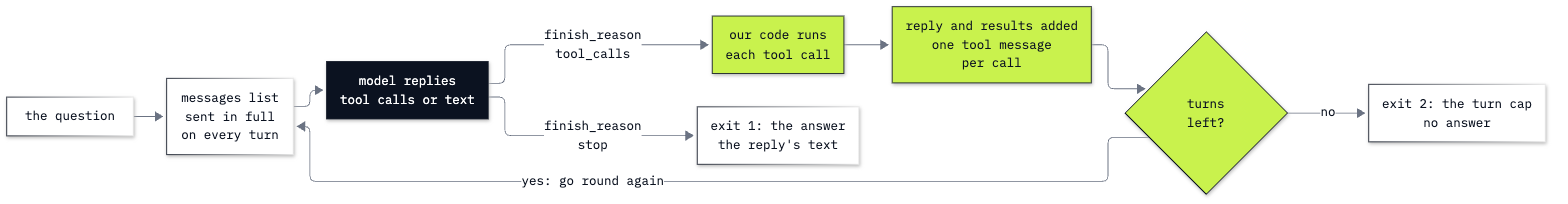

In [12]:
from IPython.display import Image

Image("resources/lab03_agent_loop.png", width=760)

How to read the drawing:

- The dark box is the one step the model does: it replies with tool calls or with text.
- The lime boxes are our code: it runs each tool call, adds the model's reply and the results to the list (one `tool`
  message per call), and checks whether turns are left.
- There are two ways out: exit 1 below the model's box, and exit 2 at the far right.

Now follow our run round it. **Turn 1:** the list goes to the model, the model replies with a tool call, our code runs
`open_envelope(1)`, adds the model's reply and the clue to the list, and the arrow goes back to the list.
**Turns 2 and 3** go round the same way, for envelopes 4 and 2. **Turn 4:** the model replies with text, and the run
leaves through exit 1, the answer.

Our `while True` loop has no exit 2 yet. Part D builds it.

**Checkpoint C.** Three `TOOL CALLED` lines, for envelopes 1, 4 and 2, in four turns; the answer names envelope 2;
the transcript has 9 messages; the prompt tokens grow on every turn.

---

## Part D: Give the loop a second exit, the turn cap

Our loop ends in one way only: the model stops asking for tools. What if it does not stop? `while True` has no other
way out, and we just saw that every extra turn costs more than the one before.

So before we test that, we give the loop an exit of our own: a **turn cap**. We also put the loop in a function,
because we will run it more than once. Two lines change:

- `for turn in range(1, max_turns + 1)` replaces `while True`. The loop can now go round `max_turns` times at
  most.
- `return` replaces `break`. An answer is returned as text. If the `for` loop runs out of turns, the function
  returns `None`: the run was stopped, and there is no answer.

In [13]:
def run_loop(question, max_turns=8):
    messages = [
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": question},
    ]

    for turn in range(1, max_turns + 1):
        response = client.chat.completions.create(
            model=MODEL, messages=messages, tools=tools, reasoning_effort=EFFORT or omit
        )
        reply = response.choices[0].message
        messages.append(reply)

        # Exit 1: the model answered
        if response.choices[0].finish_reason != "tool_calls":
            return reply.content

        for call in reply.tool_calls:
            args = json.loads(call.function.arguments)
            result = open_envelope(**args)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})

    # Exit 2: the turn cap stopped the loop, and there is no answer
    return None

### A hunt that goes in a circle

We change one envelope. Number 2 no longer holds the prize: it points back to envelope 1. The clues now go 1, 4,
2, 1, 4, 2 and so on, with no prize anywhere on the way.

Before you run it: will the loop go round until the cap stops it?

In [14]:
ENVELOPES[2] = "Clue: look in envelope 1."

print(run_loop(QUESTION))

TOOL CALLED: open_envelope(1)


TOOL CALLED: open_envelope(4)


TOOL CALLED: open_envelope(2)


The clues loop back to envelope 1, so the prize is in envelope 1.


Three `TOOL CALLED` lines, for envelopes 1, 4 and 2, and then the model stopped asking. The clue in envelope 2 sent
it back to envelope 1, which it had already opened, and it did not open it again.

Now read the reply. It says the clues loop back to envelope 1, *so the prize is in envelope 1*. That is wrong: on its
first turn this same run opened envelope 1 (the first `TOOL CALLED` line) and got back *Clue: look in envelope 4.*
Nothing the tools returned supports the claim. On most runs of this cell the reply says only that the clues go in a
circle; this one added a conclusion of its own.

This is exit 1, and the cap was never needed. The run ended normally, with a confident sentence, and the sentence is
false. A normal ending tells us the model stopped asking for tools. It does not tell us the answer is right. Notebook
2 comes back to this at the desk, where a wrong answer reaches a customer.

Can we count on the model to stop by itself? It most likely stopped here because the clue in envelope 2 named an
envelope that was already in the list. The next hunt gives it nothing like that to read.

### A hunt with no end

We write `open_envelope` again, so that every envelope points to the next number: 1 says look in 2, 2 says look in
3, and so on, for ever. `run_loop` looks the function up by its name each time it runs, so defining it again is
enough.

We keep the cap at 8. Before you run it: what will `answer` be?

In [15]:
def open_envelope(number: int) -> str:
    """Open one envelope and read what is inside."""
    print(f"TOOL CALLED: open_envelope({number})")
    return f"Clue: look in envelope {number + 1}."


answer = run_loop(QUESTION, max_turns=8)
print("answer:", answer)

TOOL CALLED: open_envelope(1)


TOOL CALLED: open_envelope(2)


TOOL CALLED: open_envelope(3)


TOOL CALLED: open_envelope(4)


TOOL CALLED: open_envelope(5)


TOOL CALLED: open_envelope(6)


TOOL CALLED: open_envelope(7)


TOOL CALLED: open_envelope(8)
answer: None


Eight `TOOL CALLED` lines, for envelopes 1 to 8, and then `answer: None`. The model asked for an envelope on every
one of its eight turns, and the cap stopped the loop.

Every clue was new, so nothing in the list said the hunt was going nowhere, and the model kept asking. With `while
True` this cell would still be running. Raise `max_turns` and it opens that many envelopes more, each call sending
a longer list than the one before.

**Why does a loop need both exits?**

- **With the model's exit alone,** the run lasts as long as the model keeps asking for tools. Nothing of ours limits
  the turns, the time or the cost.
- **With the cap alone,** we could not tell an answer from a run that was cut off. Only `finish_reason` says that
  the model finished its reply.

**Important:** the cap stops the spending. It does not produce an answer. `None` means that our code has to say so
to whoever asked, and never pass it on as a reply.

**Checkpoint D.** In the circle, three `TOOL CALLED` lines and then a reply, with no fourth envelope opened. The
reply says the clues loop (ours also named envelope 1 as the prize, wrongly). In the hunt with no end, eight `TOOL
CALLED` lines for envelopes 1 to 8, and `answer: None`.

---

## What you can do now

- Run one tool call by hand on Chat Completions: the schema, the reply with `tool_calls`, our code running the
  function, the `tool` message with the same id (Parts A and B).
- Write the loop: send the list, add the reply, stop unless `finish_reason` is `tool_calls`, run every call, add
  each result, go round again (Part C).
- Print a run's message list as a transcript, and explain why the prompt tokens grow on every turn (Part C).
- Follow a run round the drawing of the loop, and name its two exits (Parts C and D).
- Add a turn cap, and tell `None` (the cap) from an answer (Part D).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `BadRequestError: Error code: 400 - An assistant message with 'tool_calls' must be followed by tool messages responding to each 'tool_call_id'.` | the list holds a reply that asked for a tool, and no `tool` message answers it | add one `tool` message for every call in `reply.tool_calls` before the next request, or start again from a fresh `messages` list |
| `BadRequestError: Error code: 400 - Function tools with reasoning_effort are not supported for <model> in /v1/chat/completions.` | on Chat Completions this model calls tools only when the reasoning effort is `none` | set `REASONING_EFFORT=none` in `models.env` and run the first cell again |
| a cell with `while True` that never finishes | the model keeps asking for tools and the loop has no cap | interrupt the kernel (the stop button), then use `run_loop` with `max_turns` |

## Challenge

1. **Add a second tool.** Some clues point to a drawer: envelope 1 says *look in the kitchen drawer*, the kitchen
   drawer says *look in envelope 3*, and envelope 3 holds the prize. Write `open_drawer(room)` with its own
   `TOOL CALLED` print, add its schema to the tools, and make the loop run the function the model named (the name is
   in `call.function.name`; a dictionary from names to functions is one way). Part D replaced `open_envelope` with the
   endless version, which ignores `ENVELOPES`, so write the Part A version again after your new `ENVELOPES`, or restart the kernel and run every cell above *A hunt with no end*. Task 2 needs the endless version again.
   Expected: three `TOOL CALLED` lines, `open_envelope(1)`, `open_drawer(kitchen)` and `open_envelope(3)`, and an
   answer that names envelope 3.
2. **Say why the run ended.** Change the loop so that it returns two things: the answer, and the reason it stopped
   (`"answer"` or `"turn cap"`). Run it on the hunt with no end with a cap of 5.
   Expected: five `TOOL CALLED` lines, then `None` and `turn cap`.

The worked solution, run with its outputs, is in `solved/03a_meet_the_agent_loop_solution.ipynb`.

## Resources

- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool schemas, strict
  mode, tool calls and sending results back
- [OpenAI: Chat Completions API reference](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  `messages`, `tools`, `finish_reason` and `usage`
- [OpenAI Agents SDK: running agents](https://openai.github.io/openai-agents-python/running_agents/): the same loop
  as a framework runs it, with a turn cap called `max_turns`

Next: [notebook 2, the agent loop at the Chinook desk](03b_agent_loop_at_the_desk.ipynb).